# 04_baseline_comparison.ipynb
- 노트북의 목표
    - v3 데이터(interval_t1~t5 시퀀스 피처 추가)로 4개 모델 베이스라인을 비교
    - v2 베이스라인 결과와 비교하여 시퀀스 피처의 성능 기여도를 확인

## 목차
1. 환경 세팅 및 데이터 로드
2. NaN 처리 (Random Forest 전용)
3. 모델 1 — LightGBM 베이스라인
4. 모델 2 — XGBoost 베이스라인
5. 모델 3 — CatBoost 베이스라인
6. 모델 4 — Random Forest 베이스라인
7. 베이스라인 성능 종합 비교
8. v2 대비 성능 변화 확인
9. 결과 저장


### 1. 환경 세팅 및 데이터 로드

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time, os

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:.4f}'.format


라이브러리 임포트 완료


In [6]:
X_train = pd.read_csv('../data/processed/X_train_v3.csv')
X_val   = pd.read_csv('../data/processed/X_val_v3.csv')
y_train = pd.read_csv('../data/processed/y_train_v3.csv').squeeze()
y_val   = pd.read_csv('../data/processed/y_val_v3.csv').squeeze()

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}')
print(f'y_train 이탈률: {y_train.mean():.4f}')
print(f'y_val   이탈률: {y_val.mean():.4f}')


X_train: (914921, 54), X_val: (228731, 54)
y_train 이탈률: 0.5002
y_val   이탈률: 0.5002


### 2. NaN 처리 (Random Forest 전용)

In [7]:
nan_cols = [
    'avg_purchase_interval', 'std_purchase_interval',
    'freq_decay_rate', 'recent_price_ratio', 'interval_acceleration',
    'interval_t1', 'interval_t2', 'interval_t3', 'interval_t4', 'interval_t5'
]

X_train_rf = X_train.copy()
X_val_rf   = X_val.copy()

for col in nan_cols:
    if col in X_train_rf.columns:
        median_val = X_train_rf[col].median()
        X_train_rf[col] = X_train_rf[col].fillna(median_val)
        X_val_rf[col]   = X_val_rf[col].fillna(median_val)

print(f'Random Forest 전용 데이터셋 준비 완료, 결측치: {X_train_rf.isnull().sum().sum()}')


Random Forest 전용 데이터셋 준비 완료, 결측치: 0


In [ ]:
baseline_results = []

### 3. 모델 3 — LightGBM 베이스라인

In [9]:
model = lgb.LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)

start = time.time()
model.fit(X_train, y_train)
elapsed = time.time() - start

pred  = model.predict(X_val)
proba = model.predict_proba(X_val)[:, 1]

baseline_results.append({
    'model'     : 'LightGBM',
    'accuracy'  : round(accuracy_score(y_val, pred), 4),
    'auc_roc'   : round(roc_auc_score(y_val, proba), 4),
    'f1_score'  : round(f1_score(y_val, pred), 4),
    'train_time': round(elapsed, 1)
})

print(f'LightGBM 완료 — AUC: {baseline_results[-1]["auc_roc"]}, 시간: {elapsed:.1f}초')


LightGBM 완료 — AUC: 0.848, 시간: 3.0초


### 4. 모델 4 — XGBoost 베이스라인

In [10]:
model = xgb.XGBClassifier(random_state=42, n_jobs=-1, verbosity=0, eval_metric='auc', use_label_encoder=False)

start = time.time()
model.fit(X_train, y_train)
elapsed = time.time() - start

pred  = model.predict(X_val)
proba = model.predict_proba(X_val)[:, 1]

baseline_results.append({
    'model'     : 'XGBoost',
    'accuracy'  : round(accuracy_score(y_val, pred), 4),
    'auc_roc'   : round(roc_auc_score(y_val, proba), 4),
    'f1_score'  : round(f1_score(y_val, pred), 4),
    'train_time': round(elapsed, 1)
})

print(f'XGBoost 완료 — AUC: {baseline_results[-1]["auc_roc"]}, 시간: {elapsed:.1f}초')


XGBoost 완료 — AUC: 0.8482, 시간: 4.6초


### 5. 모델 5 — CatBoost 베이스라인

In [11]:
model = CatBoostClassifier(random_state=42, verbose=0)

start = time.time()
model.fit(X_train, y_train)
elapsed = time.time() - start

pred  = model.predict(X_val)
proba = model.predict_proba(X_val)[:, 1]

baseline_results.append({
    'model'     : 'CatBoost',
    'accuracy'  : round(accuracy_score(y_val, pred), 4),
    'auc_roc'   : round(roc_auc_score(y_val, proba), 4),
    'f1_score'  : round(f1_score(y_val, pred), 4),
    'train_time': round(elapsed, 1)
})

print(f'CatBoost 완료 — AUC: {baseline_results[-1]["auc_roc"]}, 시간: {elapsed:.1f}초')


CatBoost 완료 — AUC: 0.8486, 시간: 51.8초


### 6. 모델 6 — RandomForest 베이스라인

In [12]:
model = RandomForestClassifier(random_state=42, n_jobs=-1)

start = time.time()
model.fit(X_train_rf, y_train)
elapsed = time.time() - start

pred  = model.predict(X_val_rf)
proba = model.predict_proba(X_val_rf)[:, 1]

baseline_results.append({
    'model'     : 'RandomForest',
    'accuracy'  : round(accuracy_score(y_val, pred), 4),
    'auc_roc'   : round(roc_auc_score(y_val, proba), 4),
    'f1_score'  : round(f1_score(y_val, pred), 4),
    'train_time': round(elapsed, 1)
})

print(f'RandomForest 완료 — AUC: {baseline_results[-1]["auc_roc"]}, 시간: {elapsed:.1f}초')


RandomForest 완료 — AUC: 0.8368, 시간: 39.2초


### 7. 베이스라인 성능 종합 비교

In [13]:
result_df = pd.DataFrame(baseline_results).sort_values('auc_roc', ascending=False).reset_index(drop=True)
print('--- v3 베이스라인 성능 비교 (AUC 기준 정렬) ---')
print(result_df.to_string(index=False))


--- v3 베이스라인 성능 비교 (AUC 기준 정렬) ---
       model  accuracy  auc_roc  f1_score  train_time
    CatBoost    0.7687   0.8486    0.7728     51.8000
     XGBoost    0.7690   0.8482    0.7728      4.6000
    LightGBM    0.7692   0.8480    0.7725      3.0000
RandomForest    0.7602   0.8368    0.7599     39.2000


C:\Users\09048\AppData\Local\Temp\ipykernel_25376\2320266708.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=result_df, x='model', y='auc_roc', ax=axes[0], palette='viridis')
C:\Users\09048\AppData\Local\Temp\ipykernel_25376\2320266708.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=result_df, x='model', y='train_time', ax=axes[1], palette='magma')
C:\Users\09048\AppData\Local\Temp\ipykernel_25376\2320266708.py:14: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_25376\2320266708.py:14: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) Arial.
  p

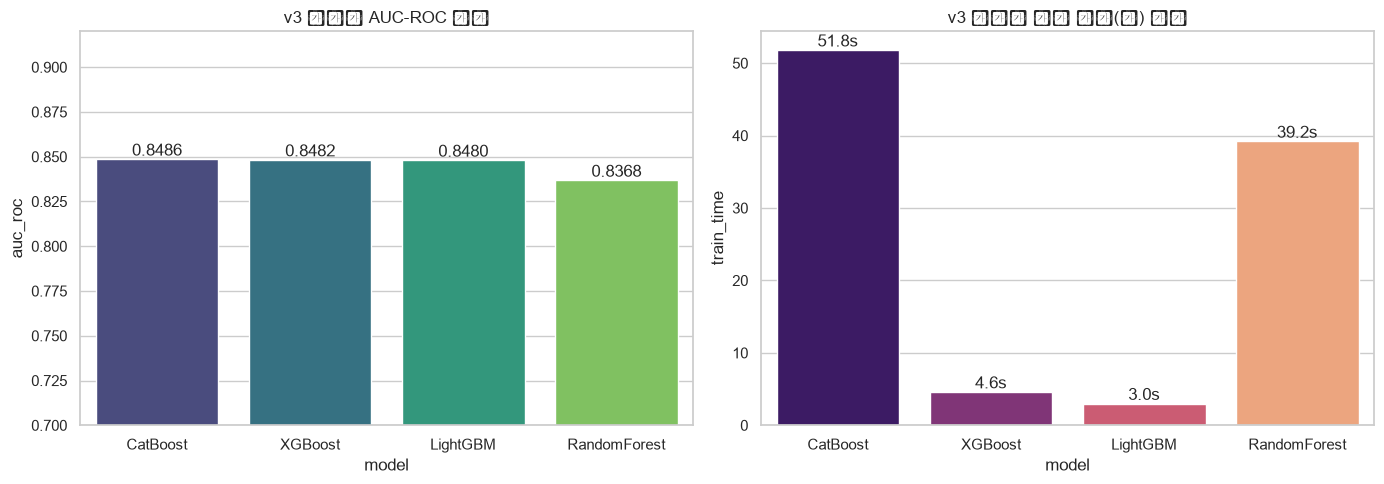

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=result_df, x='model', y='auc_roc', ax=axes[0], palette='viridis')
axes[0].set_title('v3 모델별 AUC-ROC 비교')
axes[0].set_ylim(0.7, 0.92)
for i, v in enumerate(result_df['auc_roc']):
    axes[0].text(i, v + 0.002, f'{v:.4f}', ha='center')

sns.barplot(data=result_df, x='model', y='train_time', ax=axes[1], palette='magma')
axes[1].set_title('v3 모델별 학습 시간(초) 비교')
for i, v in enumerate(result_df['train_time']):
    axes[1].text(i, v + 0.5, f'{v:.1f}s', ha='center')

plt.tight_layout(); plt.show()


### 8. v2 대비 성능 변화 확인

In [15]:
# v2 베이스라인 결과 로드
v2_results = pd.read_csv('../results/baseline_comparison_v2.csv')

print('--- v2 vs v3 AUC 비교 ---')
compare = pd.merge(result_df[['model','auc_roc']], v2_results[['model','auc_roc']],
                   on='model', suffixes=('_v3','_v2'))
compare['개선폭'] = (compare['auc_roc_v3'] - compare['auc_roc_v2']).round(4)
print(compare.to_string(index=False))

print('\n→ 개선폭이 양수이면 시퀀스 피처(interval_t1~t5)가 성능에 기여한 것')
print('→ 개선폭이 미미하면 시퀀스 정보도 기존 RFM 피처와 유사한 정보를 담고 있는 것')


FileNotFoundError: [Errno 2] No such file or directory: '../results/baseline_comparison_v2.csv'

### 9. 결과 저장

In [ ]:
os.makedirs('../results', exist_ok=True)
result_df.to_csv('../results/baseline_comparison_v3.csv', index=False)
print('베이스라인 비교 결과 저장 완료: ../results/baseline_comparison_v3.csv')

top2 = result_df.head(2)['model'].tolist()
print(f'\nAUC 기준 상위 2개 모델: {top2}')
print('→ 05_tuning 파일에서 위 2개 모델 튜닝 진행')


NameError: name 'result_df' is not defined